# Stellarator design for people who train models

A stellarator uses a twisted magnetic field to confine a plasma. Changing its shape changes how the field lines wind and how particles drift. The design problem is to find shapes with useful properties, subject to physics and engineering constraints.

Here is a small problem you can run and modify: **six shape parameters, a physics solver, and a few scalar outputs.** We approach it twice: learn from a database, then optimize through the solver's derivatives. No plasma-physics background is assumed.

The opportunity resembles what attracted ML researchers to molecular structure: a useful representation, reliable labels, and a demanding inverse problem. Here we choose a boundary to obtain desired field properties. These examples address a vacuum magnetic configuration; they do not predict fusion power or design the coils.

## Run it

Use Python 3.11 or newer. From a checkout of the branch containing these examples:

```bash
git clone --branch examples/ml-stellarator-introduction https://github.com/uwplasma/VMEX.git
cd VMEX
python -m pip install -e ".[optimizers]" jupyter
jupyter notebook examples/machine_learning/stellarator_optimization.ipynb
```

The scripts use the installed JAX backend. CPU is sufficient for the defaults; the first evaluation includes compilation. Keep 64-bit arithmetic enabled. Optional effective-ripple calculations also need `neo-jax>=1.1.1`.

Run the cells in order. Results are cached under `results/machine_learning/`; set `RERUN = True` after editing a script. The rendered plots stay in this notebook, so a recipient can read it without running anything.

In [1]:
from pathlib import Path
from dataclasses import replace
import json
import re
import os
import runpy
import numpy as np
import matplotlib.pyplot as plt
import vmex as vj

RERUN = False
REPO = Path(vj.__file__).resolve().parents[1]  # editable checkout from the command above
EXAMPLES = REPO / "examples" / "machine_learning"
RESULTS = REPO / "results" / "machine_learning"
if not (EXAMPLES / "database_optimization.py").exists():
    raise FileNotFoundError("Install the checkout containing the machine_learning examples with pip install -e .")

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 180, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#263648",
    "text.color": "#263648", "axes.prop_cycle": plt.cycler(color=["#007F86", "#DC7046", "#6C65A5"]),
    "figure.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, INK = "#007F86", "#DC7046", "#263648"
print("Using the editable VMEX checkout.")

Using the editable VMEX checkout.


## What are the trainable parameters?

We prescribe the outermost magnetic surface. VMEX solves for the nested surfaces and magnetic field inside it. For a stellarator-symmetric boundary,

\[
R(\theta,\phi)=\sum_{m,n}R_{mn}\cos(m\theta-nN_{\rm fp}\phi),\qquad
Z(\theta,\phi)=\sum_{m,n}Z_{mn}\sin(m\theta-nN_{\rm fp}\phi).
\]

Here $R$ is distance from the central vertical axis, $Z$ is height, $\theta$ goes around the tube, and $\phi$ goes around the machine. $N_{\rm fp}=2$ repeats the shape twice per turn. The input names are `RBC(n,m)` and `ZBS(n,m)`; their index order is **n, m**.

We start near the [Landreman–Paul quasi-axisymmetric configuration](https://doi.org/10.1103/PhysRevLett.128.035001). Six coefficients can move by up to 3 mm: $c_j=c_{j,0}+0.003x_j$, with $x_j\in[-1,1]$. The major-radius coefficient, toroidal flux, field-period count, pressure, and current stay fixed. Pressure and current are zero. This makes iota an output of the geometry, rather than a prescribed profile.

Six parameters are enough to learn the interface. They span only a small neighborhood of one design, not the space of stellarators.

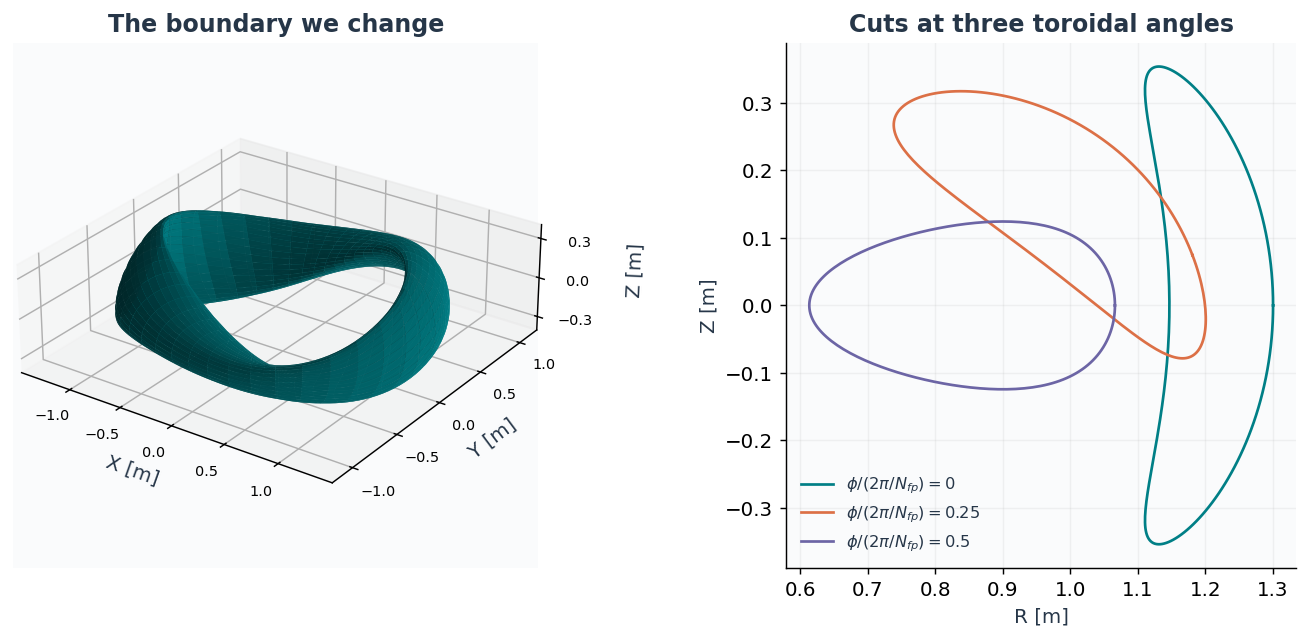

In [2]:
DOFS = (("rbc", 0, 1), ("zbs", 0, 1), ("rbc", 1, 0),
        ("zbs", 1, 0), ("rbc", 1, 1), ("zbs", 1, 1))
STEP = 0.003
seed = vj.VmecInput.from_file(REPO / "examples/data/input.LandremanPaul2021_QA_lowres")
seed = seed.change_resolution(mpol=5, ntor=5)


def boundary(x, theta, phi):
    """Evaluate the prescribed surface; this plot needs no equilibrium solve."""
    coefficients = {"rbc": seed.rbc.copy(), "zbs": seed.zbs.copy()}
    for value, (kind, n, m) in zip(x, DOFS):
        coefficients[kind][n + seed.ntor, m] += STEP * value
    n = np.arange(-seed.ntor, seed.ntor + 1)[:, None]
    m = np.arange(seed.mpol)[None, :]
    phase = np.asarray(theta)[..., None, None] * m - seed.nfp * np.asarray(phi)[..., None, None] * n
    R = np.sum(coefficients["rbc"] * np.cos(phase), axis=(-2, -1))
    Z = np.sum(coefficients["zbs"] * np.sin(phase), axis=(-2, -1))
    return R, Z


theta, phi = np.meshgrid(np.linspace(0, 2*np.pi, 65), np.linspace(0, 2*np.pi, 160))
R, Z = boundary(np.zeros(6), theta, phi)
fig = plt.figure(figsize=(11, 4.8), layout="constrained")
fig.get_layout_engine().set(wspace=.12)
ax = fig.add_subplot(121, projection="3d")
ax.plot_surface(R*np.cos(phi), R*np.sin(phi), Z, color=TEAL, linewidth=0, antialiased=True, alpha=.94)
ax.set(xlabel="X [m]", ylabel="Y [m]", zlabel="Z [m]", title="The boundary we change")
ax.set_box_aspect((1, 1, .32)); ax.view_init(elev=27, azim=-55)
ax.set_zticks([-.3, 0, .3]); ax.zaxis.labelpad = 8
ax.tick_params(labelsize=8)
ax = fig.add_subplot(122)
t = np.linspace(0, 2*np.pi, 200)
for fraction in (0, .25, .5):
    r, z = boundary(np.zeros(6), t, fraction * 2*np.pi/seed.nfp)
    ax.plot(r, z, label=rf"$\phi/(2\pi/N_{{fp}})={fraction:g}$")
ax.set(xlabel="R [m]", ylabel="Z [m]", title="Cuts at three toroidal angles", aspect="equal")
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.15)
plt.show()

Each coefficient changes a recognizable part of the shape. Below, the dashed curve changes just one parameter to `x[j] = 1`; the solid curve is the seed. The displacement is small because this is a local design experiment. Try changing `STEP` in this plotting cell to see the Fourier modes more clearly; change the scripts separately to alter the optimization domain.

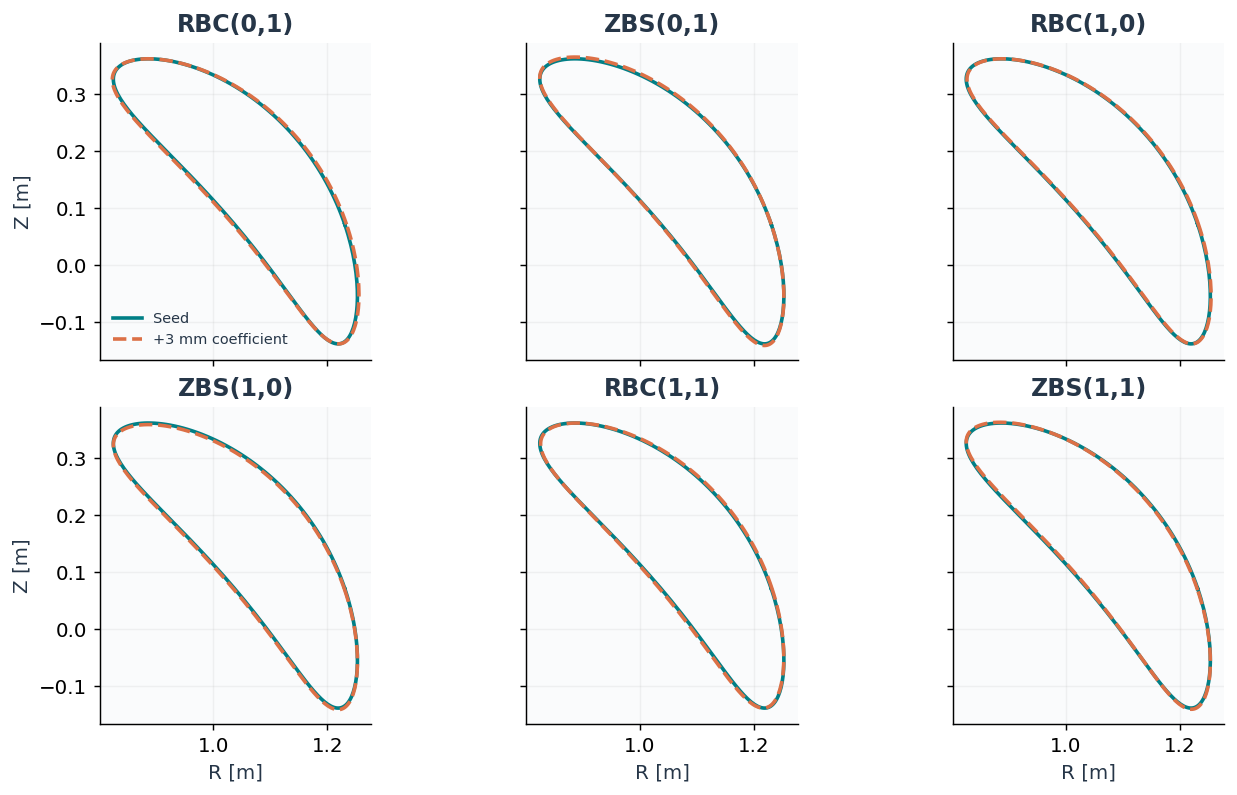

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
cut = .18 * 2*np.pi/seed.nfp
r0, z0 = boundary(np.zeros(6), t, cut)
for j, (ax, (kind, n, m)) in enumerate(zip(axes.flat, DOFS)):
    x = np.eye(6)[j]
    r, z = boundary(x, t, cut)
    ax.plot(r0, z0, color=TEAL, lw=2, label="Seed")
    ax.plot(r, z, color=ORANGE, ls="--", lw=2, label="+3 mm coefficient")
    ax.set(title=f"{kind.upper()}({n},{m})", aspect="equal")
    ax.grid(alpha=.15)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("R [m]")
for ax in axes[:, 0]:
    ax.set_ylabel("Z [m]")
plt.show()

## What comes back from the solver?

The input vector describes a boundary; the output vector describes a magnetic configuration. Keep the physical labels separate from the loss used to select a design.

| Output | Meaning | How to use it |
|---|---|---|
| Mean iota, $\bar\iota$ | Mean poloidal winding per toroidal turn; signed arithmetic mean on the half radial mesh | Match a target; a mean alone does not prevent low-iota surfaces |
| Aspect ratio, $A$ | Major radius divided by effective minor radius | Keep a desired compactness |
| Quasisymmetry (QS) residual | Departure from a symmetry of field strength in Boozer magnetic coordinates; here quasi-axisymmetry | Smaller is better for this symmetry target |
| Constructed QI residual | Departure from a constructed quasi-isodynamic field, with poloidally closed strength contours and vanishing orbit-averaged radial drift in the ideal limit | Alternative confinement objective to QS |
| $\Gamma_c$ | Bounce-averaged fast-particle drift-alignment proxy | Smaller is favorable; it is not a lost-particle fraction |
| Mapped pwO residual | Field-strength variation across a specified piecewise-omnigenous construction | A construction proxy; a small residual does not certify piecewise omnigenity or confinement |
| $\epsilon_{\rm eff}^{3/2}$ | Effective-ripple measure entering neoclassical transport in the $1/\nu$ regime | Report the exponent; it is not total plasma transport |
| Magnetic well | $(V'(0)-V'(1))/V'(0)$, with $V'=dV/ds$ and $V$ the enclosed volume | Positive is favorable; this is not a finite-pressure stability certificate |

Boozer angles differ from the boundary angles above; QS is a symmetry of field strength, not of the geometric surface. Here $s$ is toroidal flux divided by its boundary value, from 0 on axis to 1 at the boundary. Surface selection, spatial resolution, and diagnostic quadrature are part of a label's definition. The database script exposes all eight quantities; expensive diagnostics are opt-in. Failed solves and unavailable labels are retained as missing values with error information.

QS, QI, and pwO describe different design strategies. We do not minimize every row at once. The default teaching loss is simply

\[
L=\frac12\left(\frac{\bar\iota-0.45}{0.05}\right)^2+
\frac12\left(\frac{A-6}{0.5}\right)^2.
\]

This loss does not penalize QS or magnetic well; improving it can worsen confinement-related metrics. The denominators express preferences, not measurement uncertainty. Changing them changes the design problem.

## 1. Learn from a database

`database_optimization.py` samples the six-dimensional box, solves each configuration, and stores named labels in a NumPy archive. It fits a small surrogate using a fixed training split, checks held-out predictions against a constant baseline, and asks the surrogate for a promising boundary. VMEX then evaluates that proposal independently.

This is a modest baseline you can replace with a neural network, Gaussian process, ensemble, or active-learning strategy. A held-out split within this box measures local interpolation; it does not measure transfer to another stellarator family. Keep entire design families or optimization trajectories together when splitting a larger database.

In [4]:
def complete_cache(path, required):
    """An interrupted database run may have saved samples but no fitted model."""
    if not path.exists():
        return False
    with np.load(path, allow_pickle=False) as archive:
        return set(required).issubset(archive.files)


previous_directory = Path.cwd()
try:
    os.chdir(REPO)
    if RERUN or not complete_cache(RESULTS / "database.npz", ["test_predictions", "proposal_y"]):
        runpy.run_path(str(EXAMPLES / "database_optimization.py"))
finally:
    os.chdir(previous_directory)
database = np.load(RESULTS / "database.npz", allow_pickle=False)
print("Loaded the database and its independent proposal check.")

Loaded the database and its independent proposal check.


65 boundaries × 6 parameters; 65 complete basic-label rows
Stored labels: mean_iota, aspect_ratio, qs_qa_total, magnetic_well, constructed_qi_total, gamma_c_mean, mapped_pwo_total, epsilon_eff_3_2_mean
Train/test counts: {'train': 49, 'test': 16}
Failed or disabled labels stay NaN. Filter with valid[:, column] before fitting.


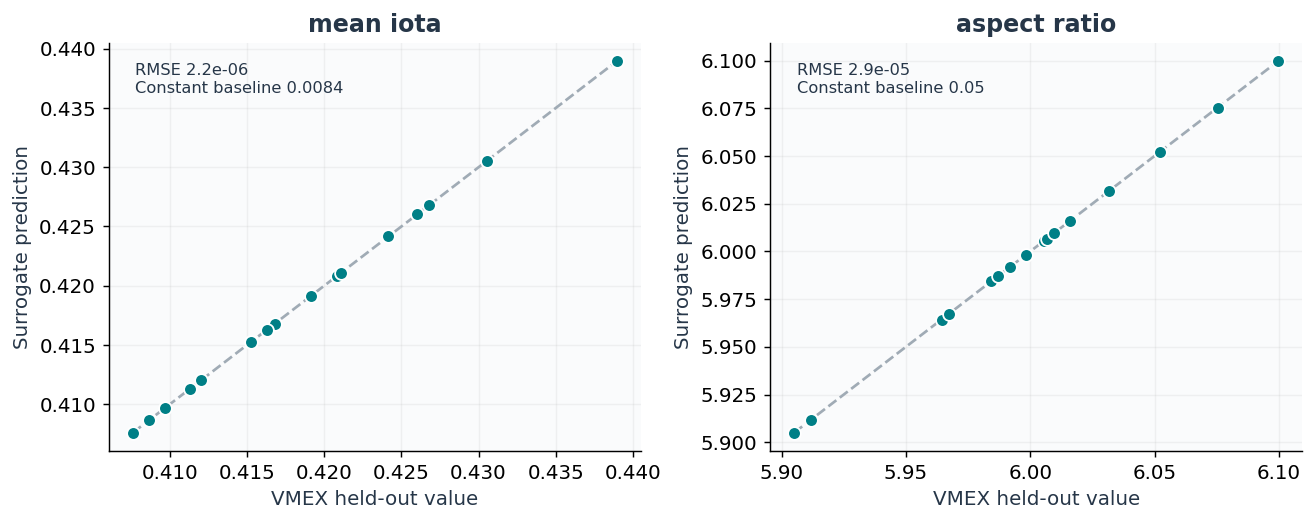

In [5]:
labels = database["label_names"].tolist()
X, Y = database["X"], database["Y"]
valid = database["valid"]
print(f"{len(X)} boundaries × {X.shape[1]} parameters; {int(valid[:, :4].all(axis=1).sum())} complete basic-label rows")
print("Stored labels:", ", ".join(labels))
print("Train/test counts:", {s: int(np.sum(database["split"] == s)) for s in ("train", "test")})
print("Failed or disabled labels stay NaN. Filter with valid[:, column] before fitting.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
for j, ax in zip((0, 1), axes):
    use = np.isfinite(database["test_predictions"][:, j]) & valid[:, j]
    truth, prediction = Y[use, j], database["test_predictions"][use, j]
    limits = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(limits, limits, "--", color="#A0ABB5", lw=1.5, label="Perfect prediction")
    ax.scatter(truth, prediction, s=50, color=TEAL, edgecolor="white", zorder=3)
    ax.set(xlabel="VMEX held-out value", ylabel="Surrogate prediction", title=labels[j].replace("_", " "))
    ax.text(.05, .95, f"RMSE {database['rmse'][j]:.2g}\nConstant baseline {database['baseline_rmse'][j]:.2g}",
            va="top", transform=ax.transAxes, fontsize=9)
    ax.grid(alpha=.15)
plt.show()

A model can predict local labels well and still exploit its own errors during optimization. Keep the proposed design separate from its verified value. If the independent solve fails or its true loss is worse, the script keeps the seed. This same check belongs after a neural generator or a surrogate optimizer.

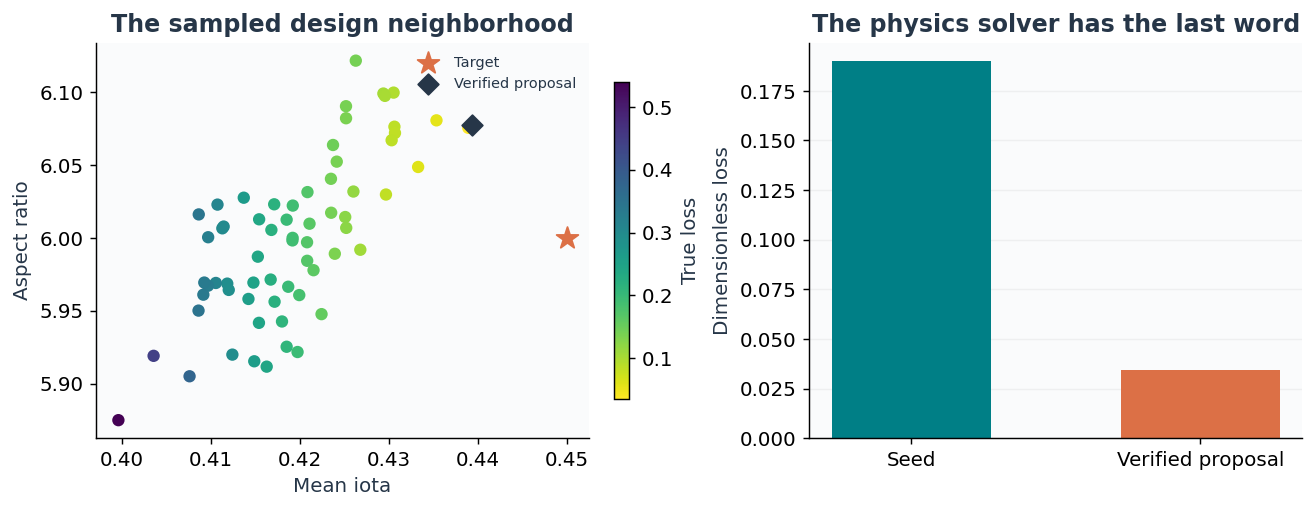

In [6]:
metadata = json.loads(str(database["provenance"]))
targets = np.array([metadata["target_iota"], metadata["target_aspect"]])
scales = np.array([metadata["iota_scale"], metadata["aspect_scale"]])

def teaching_loss(values):
    return .5 * np.sum(((np.asarray(values)[..., :2] - targets) / scales)**2, axis=-1)

seed_loss = float(teaching_loss(Y[0]))
proposal_loss = float(teaching_loss(database["proposal_y"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
keep = valid[:, :2].all(axis=1)
points = axes[0].scatter(Y[keep, 0], Y[keep, 1], c=teaching_loss(Y[keep]), cmap="viridis_r", s=34)
axes[0].scatter(*targets, marker="*", s=160, color=ORANGE, label="Target", zorder=5)
axes[0].scatter(*database["proposal_y"][:2], marker="D", s=65, color=INK, label="Verified proposal", zorder=4)
axes[0].set(xlabel="Mean iota", ylabel="Aspect ratio", title="The sampled design neighborhood")
axes[0].legend(frameon=False, fontsize=8)
fig.colorbar(points, ax=axes[0], label="True loss", shrink=.8)
axes[1].bar(["Seed", "Verified proposal"], [seed_loss, proposal_loss], color=[TEAL, ORANGE], width=.55)
axes[1].set(ylabel="Dimensionless loss", title="The physics solver has the last word")
axes[1].grid(axis="y", alpha=.15); axes[1].set_axisbelow(True)
plt.show()

## 2. Differentiate through the physics

`differentiable_optimization.py` uses the same six parameters and target loss. The core interface is ordinary JAX and Optax:

```python
value, gradient = jax.value_and_grad(loss)(x)
updates, optimizer_state = optimizer.update(gradient, optimizer_state, x)
x = jnp.clip(optax.apply_updates(x, updates), -1, 1)
```

The learned variables here are the shape coefficients themselves. There is no neural network to train. You can also put a network upstream of this loss, or use these gradients as labels for a surrogate.

If $u$ denotes the equilibrium state and $F(u,x)=0$ its discrete equations, the derivative follows from

\[
F_u\,du/dx=-F_x.
\]

For a scalar loss, an adjoint solve computes the gradient without storing the forward iteration history. The first call includes JAX compilation; later calls reuse it. This is a derivative of the discretized equilibrium, conditional on convergence and a well-defined local branch. Automatic differentiation does not remove spatial or quadrature error.

The script checks a directional derivative at three step sizes using independently converged perturbed boundaries, runs Adam, then independently solves the initial and best boundaries again at the original and a finer radial grid. The angular resolution is unchanged; this is a partial refinement check. Adam is used because its interface is familiar, not because it is the best optimizer for six parameters. L-BFGS-B and least-squares methods are useful comparisons.

In [7]:
try:
    os.chdir(REPO)
    if RERUN or not complete_cache(RESULTS / "differentiation.npz", ["refined_loss", "fd_steps"]):
        runpy.run_path(str(EXAMPLES / "differentiable_optimization.py"))
finally:
    os.chdir(previous_directory)
training = np.load(RESULTS / "differentiation.npz", allow_pickle=False)
print(f"First gradient: {float(training['cold_gradient_seconds']):.2f} s; repeated gradient: {float(training['warm_gradient_seconds']):.2f} s")
print("Independent initial / selected losses:", training["verification_loss"])
print("Targets are preferences: the best point need not meet both exactly.")

First gradient: 8.56 s; repeated gradient: 0.28 s
Independent initial / selected losses: [0.18980141 0.03004863]
Targets are preferences: the best point need not meet both exactly.


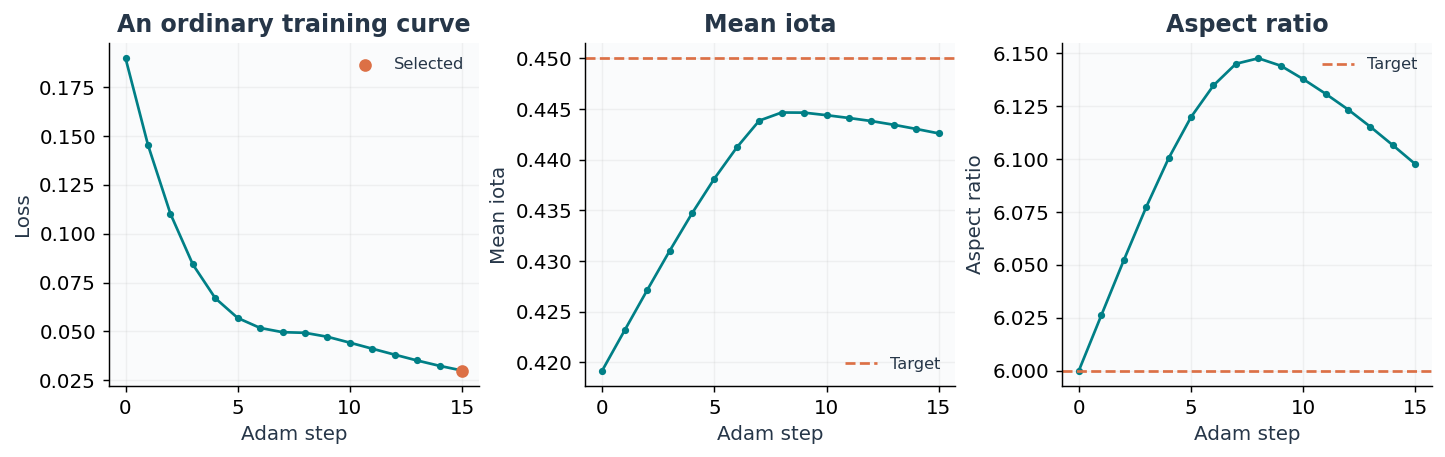

In [8]:
history = training["metrics_history"]
best = int(training["best_index"])
steps = np.arange(len(history))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), layout="constrained")
axes[0].plot(steps, training["loss_history"], color=TEAL, marker=".")
axes[0].scatter(best, training["loss_history"][best], color=ORANGE, zorder=4, label="Selected")
axes[0].set(ylabel="Loss", title="An ordinary training curve")
axes[0].legend(frameon=False, fontsize=9)
for j, label in enumerate(("Mean iota", "Aspect ratio")):
    axes[j+1].plot(steps, history[:, j], color=TEAL, marker=".")
    axes[j+1].axhline(training["targets"][j], color=ORANGE, ls="--", lw=1.5, label="Target")
    axes[j+1].set(ylabel=label, title=label)
    axes[j+1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.set_xlabel("Adam step"); ax.grid(alpha=.15)
plt.show()

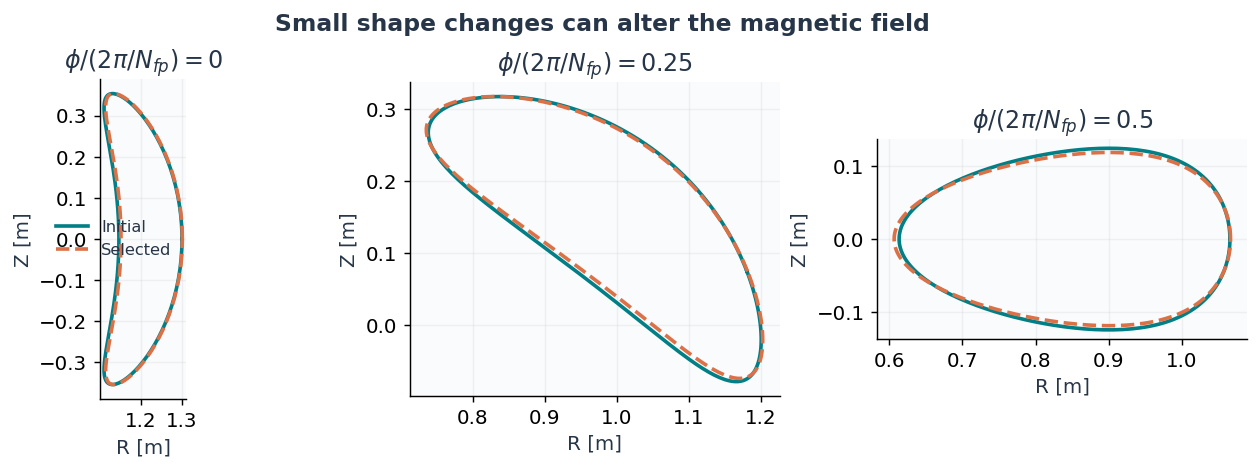

Selected normalized coefficients: [ 0.271 -0.956  1.    -1.    -1.     1.   ]


In [9]:
# Reconstruct from saved parameters, including any edits made to the script.
seed = replace(seed, rbc=training["rbc_seed"], zbs=training["zbs_seed"],
               ntor=int(training["ntor"]), mpol=training["rbc_seed"].shape[1], nfp=int(training["nfp"]))
STEP = float(training["step"])
DOFS = []
for name in training["dof_names"]:
    kind, n, m = re.fullmatch(r"(RBC|ZBS)\((-?\d+),(\d+)\)", str(name)).groups()
    DOFS.append((kind.lower(), int(n), int(m)))
chosen = training["x_history"][best]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
for ax, fraction in zip(axes, (0, .25, .5)):
    for x, color, label, style in ((np.zeros(len(DOFS)), TEAL, "Initial", "-"),
                                  (chosen, ORANGE, "Selected", "--")):
        r, z = boundary(x, t, fraction * 2*np.pi/seed.nfp)
        ax.plot(r, z, color=color, label=label, ls=style, lw=2)
    ax.set(xlabel="R [m]", ylabel="Z [m]", title=rf"$\phi/(2\pi/N_{{fp}})={fraction:g}$", aspect="equal")
    ax.grid(alpha=.15)
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Small shape changes can alter the magnetic field", fontsize=13, fontweight="bold")
plt.show()
print("Selected normalized coefficients:", np.round(chosen, 3))

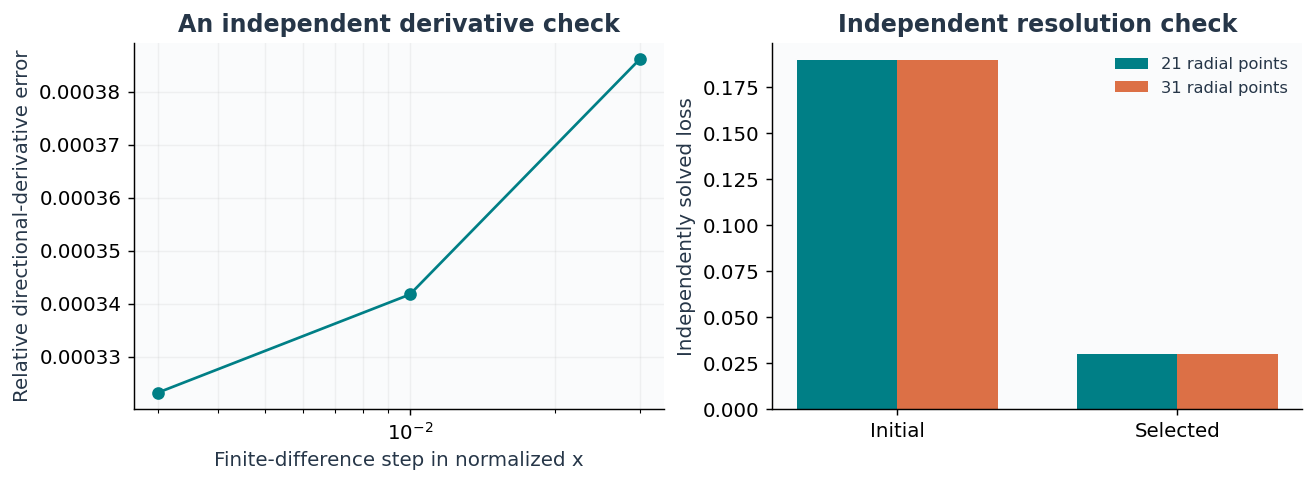

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].semilogx(training["fd_steps"], training["fd_errors"], "o-", color=TEAL)
axes[0].set(xlabel="Finite-difference step in normalized x", ylabel="Relative directional-derivative error",
            title="An independent derivative check")
axes[0].grid(alpha=.15, which="both")
positions = np.arange(2)
training_metadata = json.loads(str(training["provenance"]))
original_ns = training_metadata["input"]["ns_array"][-1]
axes[1].bar(positions-.18, training["verification_loss"], width=.36, color=TEAL, label=f"{original_ns} radial points")
axes[1].bar(positions+.18, training["refined_loss"], width=.36, color=ORANGE, label=f"{int(training['ns_verify'])} radial points")
axes[1].set(xticks=positions, xticklabels=["Initial", "Selected"], ylabel="Independently solved loss",
            title="Independent resolution check")
axes[1].legend(frameon=False, fontsize=9)
plt.show()

## Experiments worth trying

1. **Change the optimizer.** Keep the starting point, parameter bounds, loss, and evaluation budget fixed. Compare Adam with L-BFGS-B, a derivative-free method, or your optimizer. Report wall time, first-call compilation, physics evaluations, and independently verified final loss.
2. **Change the learner.** Replace the database response surface with a small network or ensemble. Compare against the existing baseline before adding capacity. Query VMEX where uncertainty is high or a candidate looks promising, then retrain.
3. **Change the physics objective.** Add a QA residual or a magnetic-well floor. For a floor, penalize only violations. QI and pwO are alternative design directions; a weighted sum of every available metric has no automatic physical justification.
4. **Try a larger design space.** Add Fourier coefficients gradually and reduce their allowed amplitude at higher mode number. Hold out whole starting configurations when measuring generalization. Fix scale and angle conventions before mixing databases.
5. **Check what the optimizer found.** Increase equilibrium and diagnostic resolution, repeat the gradient check over several perturbation sizes, inspect the iota profile, and evaluate confinement independently. A better coarse-grid loss can disappear on a finer grid.

The default examples do not optimize coils, island formation, finite-pressure stability, turbulence, or engineering limits. VMEX assumes nested flux surfaces. Treat these results as small numerical experiments, then add the physics needed for your research question.

## Data and code for larger studies

- [ConStellaration](https://arxiv.org/abs/2506.19583): QI-like boundary data and constrained optimization benchmarks, with [reference code](https://github.com/proximafusion/constellaration) and a [dataset](https://huggingface.co/datasets/proxima-fusion/constellaration). Preserve the release, coordinate conventions, pressure/current settings, and label definitions when comparing results.
- [QUASR](https://quasr.flatironinstitute.org/): quasisymmetric configurations and associated coils, useful when moving from boundary design to coil geometry.
- [BoSS](https://arxiv.org/abs/2610.37910): a 2026 preprint and [fast-ion simulation dataset](https://boss.flatironinstitute.org/), for questions that require particle information beyond equilibrium proxies.
- [DESC](https://github.com/PlasmaControl/DESC) and [SIMSOPT](https://github.com/hiddenSymmetries/simsopt): alternative equilibrium and optimization tools. Their data and objective normalizations are not interchangeable by name alone.

## A short reading path

- [Landreman & Paul (2022)](https://doi.org/10.1103/PhysRevLett.128.035001): the quasi-axisymmetric seed and why magnetic symmetry matters.
- [VMEX objective definitions](https://vmex.readthedocs.io/en/latest/reference/objectives.html): the quantities used by the scripts, including conventions and limitations.
- [VMEX adjoint gradients](https://vmex.readthedocs.io/en/latest/explanation/adjoint-gradients.html): what the implicit derivative represents and how to check it.
- [Goodman et al. (2023)](https://arxiv.org/abs/2211.09829): constructing nearly quasi-isodynamic fields.
- [Velasco et al. (2024)](https://arxiv.org/abs/2405.07634): the definition of piecewise omnigenity; [Liu et al. (2026)](https://arxiv.org/abs/2603.12139) describes the mapped construction used here.
- [Velasco et al. (2021)](https://arxiv.org/abs/2106.05697): fast-ion proxies and their relationship to prompt losses; [Nemov et al. (1999)](https://doi.org/10.1063/1.873749) defines effective ripple.
- [Merlo et al.](https://arxiv.org/abs/2211.09743): a physics-regularized equilibrium surrogate. The ConStellaration paper above provides an ML benchmark.

If you send this notebook to someone: the plots are the starting point; ask them to change one target or replace one optimizer, then check the result with VMEX.